# Projeto 02 - Inteligência Artificial (2026)
## Notebook 01: Análise Exploratória de Dados (EDA)

---

### Identificação do Grupo e Alunos
* **Grupo:** G51233
* **Aluno 1:** 51233 - Lucas Lima Magalhães *(Contribuição: 100%)*

---

### Contexto do Trabalho
Este notebook compreende a **Fase de Análise Exploratória de Dados (EDA)** do Projeto 02 da disciplina de Inteligência Artificial. O objetivo central é investigar em detalhe a estrutura, distribuição, correlações, inconsistências e padrões intrínsecos de dois conjuntos de dados reais:
1. **Housing (California Housing Prices):** Dados censitários de blocos habitacionais na Califórnia, utilizados primordialmente para tarefas de regressão, agrupamento espacial e mineração de regras.
2. **Home Credit (Credit Risk Dataset):** Registos cadastrais e financeiros de proponentes a crédito, com objetivo de avaliar o risco de incumprimento (*loan default*).

Nesta etapa, estabelecemos a fundamentação empírica indispensável para as fases subsequentes de modelagem preditiva supervisionada (Árvores de Decisão *from scratch*), agrupamento não supervisionado (K-Means *from scratch*) e extração de regras de associação (Apriori).


## 1. Fontes dos Datasets e Metadados Formais

Conforme exigido na especificação do projeto, os dados foram obtidos de repositórios públicos abertos via `kagglehub`. A tabela abaixo consolida as origens exatas, autoria e escopo de cada base:

| Dataset | Origem / URL Oficial | Autor / Repositório Kaggle | Registos | Atributos | Variável-Alvo |
| :--- | :--- | :--- | :---: | :---: | :---: |
| **Housing** | [California Housing Prices](https://www.kaggle.com/datasets/camnugent/california-housing-prices) | `camnugent/california-housing-prices` | 20.640 | 10 (9 num, 1 cat) | `median_house_value` |
| **Home Credit** | [Credit Risk Dataset](https://www.kaggle.com/datasets/laotse/credit-risk-dataset) | `laotse/credit-risk-dataset` | 32.581 | 12 (8 num, 4 cat) | `loan_status` (0: Adimplente, 1: Default) |

A amostra balanceada reprodutível de Home Credit (`data/home_credit_sample.csv`, $N=5.000$) preserva rigorosamente a distribuição de classes ($78.2\%$ adimplentes vs $21.8\%$ inadimplentes) com semente `random_state=42`.


In [1]:
# Configuração do ambiente e importação das bibliotecas analíticas e módulos core
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Ajuste estético das figuras
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11

# Importação dos módulos locais de suporte
sys.path.append(os.path.abspath('..'))
from src.download_data import DATASET_SOURCES

print("Módulos carregados com sucesso!")
print("Fontes registadas no sistema:")
for k, v in DATASET_SOURCES.items():
    print(f" - {v['name']}: {v['url']}")

Módulos carregados com sucesso!
Fontes registadas no sistema:
 - California Housing Prices: https://www.kaggle.com/datasets/camnugent/california-housing-prices
 - Home Credit / Credit Risk Dataset: https://www.kaggle.com/datasets/laotse/credit-risk-dataset


In [2]:
# Carregamento dos ficheiros CSV gerados na FASE 0
housing_path = os.path.join('data', 'housing.csv')
credit_path = os.path.join('data', 'home_credit.csv')
credit_sample_path = os.path.join('data', 'home_credit_sample.csv')

df_housing = pd.read_csv(housing_path)
df_credit = pd.read_csv(credit_path)
df_credit_sample = pd.read_csv(credit_sample_path)

print(f"Dataset Housing: {df_housing.shape[0]:,} linhas e {df_housing.shape[1]} colunas.")
print(f"Dataset Home Credit (Full): {df_credit.shape[0]:,} linhas e {df_credit.shape[1]} colunas.")
print(f"Dataset Home Credit (Amostra): {df_credit_sample.shape[0]:,} linhas e {df_credit_sample.shape[1]} colunas.")

Dataset Housing: 20,640 linhas e 10 colunas.
Dataset Home Credit (Full): 32,581 linhas e 12 colunas.
Dataset Home Credit (Amostra): 5,000 linhas e 12 colunas.


## 2. Inspeção Estrutural e Qualidade dos Dados

Examinamos as variáveis, tipos de dados e identificamos eventuais valores ausentes (*missing values*).


In [3]:
# Metadados e contagem de nulos: Housing
housing_meta = pd.DataFrame({
    'Tipo': df_housing.dtypes,
    'Valores Únicos': df_housing.nunique(),
    'Nulos (Qtd)': df_housing.isnull().sum(),
    'Nulos (%)': (df_housing.isnull().sum() / len(df_housing)) * 100
})
print("=== METADADOS: HOUSING ===")
display(housing_meta)

=== METADADOS: HOUSING ===


,Tipo,Valores Únicos,Nulos (Qtd),Nulos (%)
longitude,float64,844,0,0.000000
latitude,float64,862,0,0.000000
housing_median_age,float64,52,0,0.000000
total_rooms,float64,5926,0,0.000000
total_bedrooms,float64,1923,207,1.002907
population,float64,3888,0,0.000000
households,float64,1815,0,0.000000
median_income,float64,12928,0,0.000000
median_house_value,float64,3842,0,0.000000
ocean_proximity,str,5,0,0.000000


In [4]:
# Metadados e contagem de nulos: Home Credit
credit_meta = pd.DataFrame({
    'Tipo': df_credit.dtypes,
    'Valores Únicos': df_credit.nunique(),
    'Nulos (Qtd)': df_credit.isnull().sum(),
    'Nulos (%)': (df_credit.isnull().sum() / len(df_credit)) * 100
})
print("=== METADADOS: HOME CREDIT ===")
display(credit_meta)

=== METADADOS: HOME CREDIT ===


,Tipo,Valores Únicos,Nulos (Qtd),Nulos (%)
person_age,int64,58,0,0.000000
person_income,int64,4295,0,0.000000
person_home_ownership,str,4,0,0.000000
person_emp_length,float64,36,895,2.747000
loan_intent,str,6,0,0.000000
loan_grade,str,7,0,0.000000
loan_amnt,int64,753,0,0.000000
loan_int_rate,float64,348,3116,9.563856
loan_status,int64,2,0,0.000000
loan_percent_income,float64,77,0,0.000000


## 3. Análise Univariada: Estatísticas Descritivas e Distribuições

Abaixo calculamos as estatísticas de tendência central, dispersão, assimetria (*skewness*) e curtose para as variáveis numéricas dos dois conjuntos de dados.


In [5]:
# Estatísticas descritivas detalhadas - Housing
desc_housing = df_housing.describe().T
desc_housing['skew'] = df_housing.select_dtypes(include=[np.number]).skew()
desc_housing['kurtosis'] = df_housing.select_dtypes(include=[np.number]).kurtosis()
print("=== ESTATÍSTICAS NUMÉRICAS: HOUSING ===")
display(desc_housing[['mean', 'std', 'min', '50%', 'max', 'skew', 'kurtosis']])

=== ESTATÍSTICAS NUMÉRICAS: HOUSING ===


,mean,std,min,50%,max,skew,kurtosis
longitude,-119.569704,2.003532,-124.3500,-118.4900,-114.3100,-0.297801,-1.330152
latitude,35.631861,2.135952,32.5400,34.2600,41.9500,0.465953,-1.117760
housing_median_age,28.639486,12.585558,1.0000,29.0000,52.0000,0.060331,-0.800629
total_rooms,2635.763081,2181.615252,2.0000,2127.0000,39320.0000,4.147343,32.630927
total_bedrooms,537.870553,421.385070,1.0000,435.0000,6445.0000,3.459546,21.985575
population,1425.476744,1132.462122,3.0000,1166.0000,35682.0000,4.935858,73.553116
households,499.539680,382.329753,1.0000,409.0000,6082.0000,3.410438,22.057988
median_income,3.870671,1.899822,0.4999,3.5348,15.0001,1.646657,4.952524
median_house_value,206855.816909,115395.615874,14999.0000,179700.0000,500001.0000,0.977763,0.327870


In [6]:
# Estatísticas descritivas detalhadas - Home Credit
desc_credit = df_credit.describe().T
desc_credit['skew'] = df_credit.select_dtypes(include=[np.number]).skew()
desc_credit['kurtosis'] = df_credit.select_dtypes(include=[np.number]).kurtosis()
print("=== ESTATÍSTICAS NUMÉRICAS: HOME CREDIT ===")
display(desc_credit[['mean', 'std', 'min', '50%', 'max', 'skew', 'kurtosis']])

=== ESTATÍSTICAS NUMÉRICAS: HOME CREDIT ===


,mean,std,min,50%,max,skew,kurtosis
person_age,27.734600,6.348078,20.00,26.00,144.00,2.581393,18.560825
person_income,66074.848470,61983.119168,4000.00,55000.00,6000000.00,32.865349,2693.272776
person_emp_length,4.789686,4.142630,0.00,4.00,123.00,2.614455,43.722338
loan_amnt,9589.371106,6322.086646,500.00,8000.00,35000.00,1.192477,1.423565
loan_int_rate,11.011695,3.240459,5.42,10.99,23.22,0.208550,-0.671609
loan_status,0.218164,0.413006,0.00,0.00,1.00,1.364888,-0.137088
loan_percent_income,0.170203,0.106782,0.00,0.15,0.83,1.064669,1.223687
cb_person_cred_hist_length,5.804211,4.055001,2.00,4.00,30.00,1.661790,3.716194


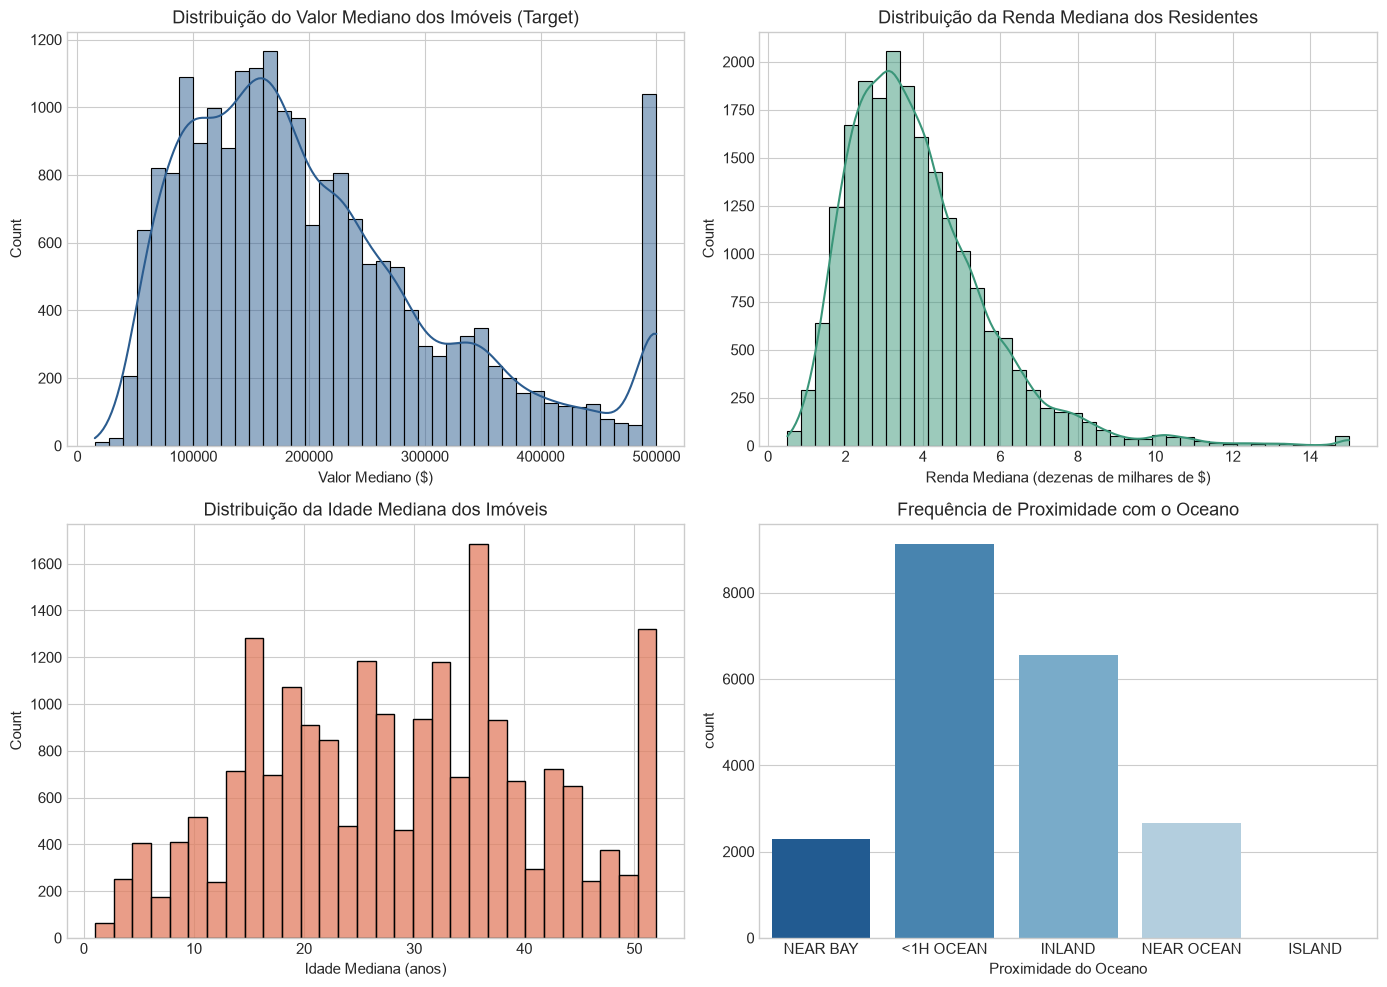

In [7]:
# Visualização univariada das variáveis principais do Housing
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Valor mediano da casa (target)
sns.histplot(df_housing['median_house_value'], kde=True, ax=axes[0, 0], color='#2b5c8f', bins=40)
axes[0, 0].set_title("Distribuição do Valor Mediano dos Imóveis (Target)")
axes[0, 0].set_xlabel("Valor Mediano ($)")

# 2. Renda mediana
sns.histplot(df_housing['median_income'], kde=True, ax=axes[0, 1], color='#3a9679', bins=40)
axes[0, 1].set_title("Distribuição da Renda Mediana dos Residentes")
axes[0, 1].set_xlabel("Renda Mediana (dezenas de milhares de $)")

# 3. Idade mediana do imóvel
sns.histplot(df_housing['housing_median_age'], kde=False, ax=axes[1, 0], color='#e27d60', bins=30)
axes[1, 0].set_title("Distribuição da Idade Mediana dos Imóveis")
axes[1, 0].set_xlabel("Idade Mediana (anos)")

# 4. Categoria ocean_proximity
sns.countplot(data=df_housing, x='ocean_proximity', hue='ocean_proximity', legend=False, ax=axes[1, 1], palette='Blues_r')
axes[1, 1].set_title("Frequência de Proximidade com o Oceano")
axes[1, 1].set_xlabel("Proximidade do Oceano")

plt.tight_layout()
plt.show()

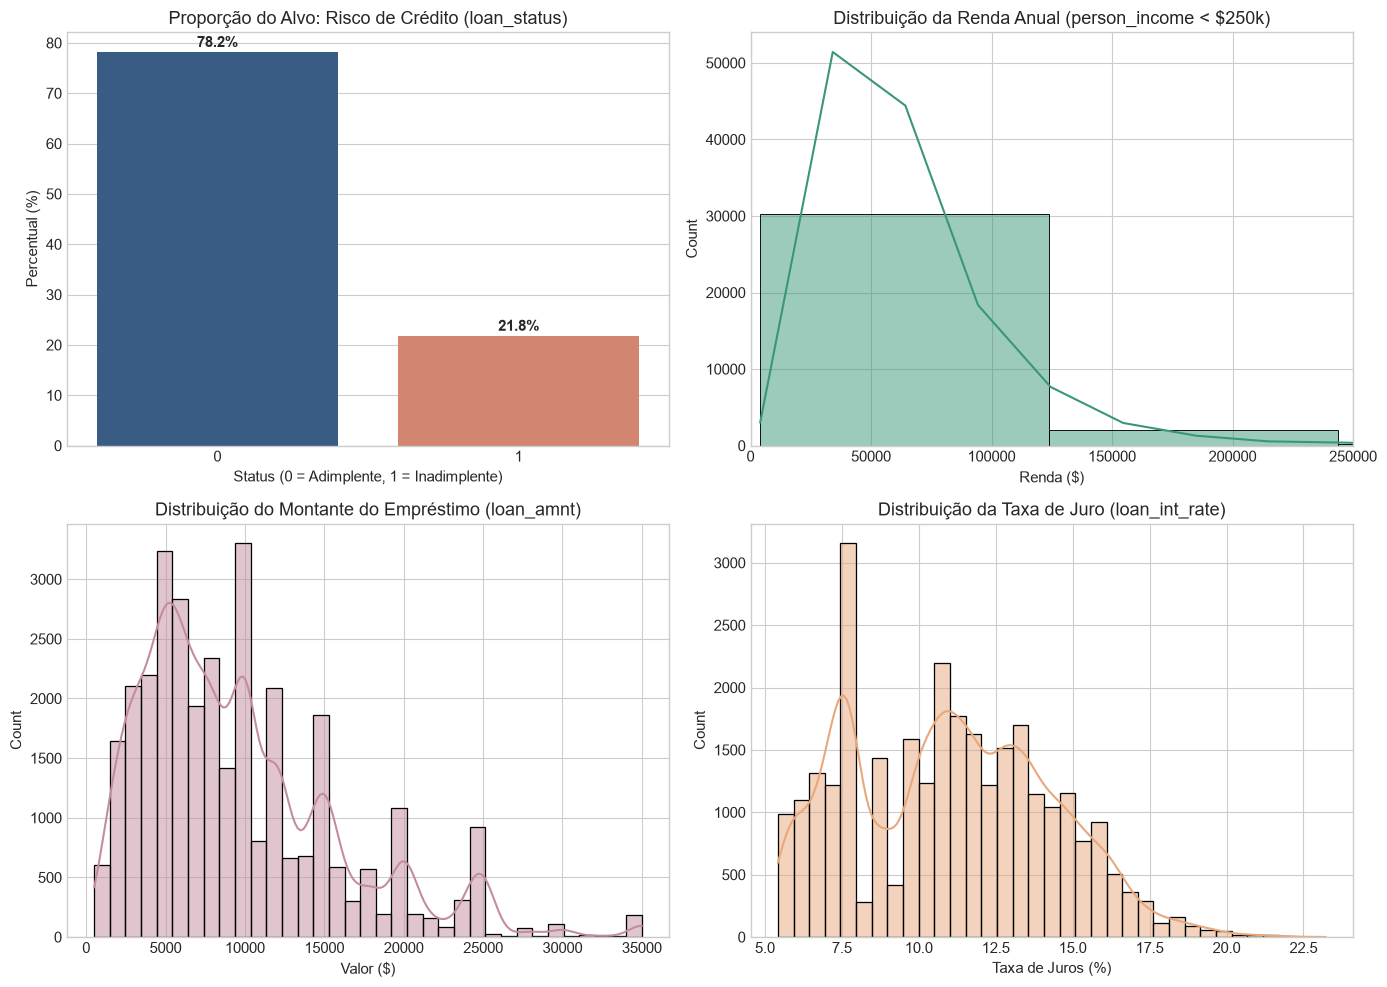

In [8]:
# Visualização univariada do Home Credit (Alvo e principais covariáveis)
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Proporção da classe alvo (loan_status)
target_counts = df_credit['loan_status'].value_counts(normalize=True) * 100
sns.barplot(x=target_counts.index, y=target_counts.values, hue=target_counts.index, legend=False, ax=axes[0, 0], palette=['#2b5c8f', '#e27d60'])
axes[0, 0].set_title("Proporção do Alvo: Risco de Crédito (loan_status)")
axes[0, 0].set_xlabel("Status (0 = Adimplente, 1 = Inadimplente)")
axes[0, 0].set_ylabel("Percentual (%)")
for i, v in enumerate(target_counts.values):
    axes[0, 0].text(i, v + 1, f"{v:.1f}%", ha='center', fontweight='bold')

# 2. Distribuição da renda do tomador
sns.histplot(df_credit['person_income'], kde=True, ax=axes[0, 1], color='#3a9679', bins=50)
axes[0, 1].set_xlim(0, 250000) # zoom para representação legível
axes[0, 1].set_title("Distribuição da Renda Anual (person_income < $250k)")
axes[0, 1].set_xlabel("Renda ($)")

# 3. Valor do empréstimo
sns.histplot(df_credit['loan_amnt'], kde=True, ax=axes[1, 0], color='#c38d9e', bins=35)
axes[1, 0].set_title("Distribuição do Montante do Empréstimo (loan_amnt)")
axes[1, 0].set_xlabel("Valor ($)")

# 4. Taxa de juros do empréstimo
sns.histplot(df_credit['loan_int_rate'].dropna(), kde=True, ax=axes[1, 1], color='#e8a87c', bins=35)
axes[1, 1].set_title("Distribuição da Taxa de Juro (loan_int_rate)")
axes[1, 1].set_xlabel("Taxa de Juros (%)")

plt.tight_layout()
plt.show()

## 4. Análise Bivariada e Correlações

Investigamos as relações mútuas entre covariáveis e entre as variáveis explicativas e a variável-alvo.


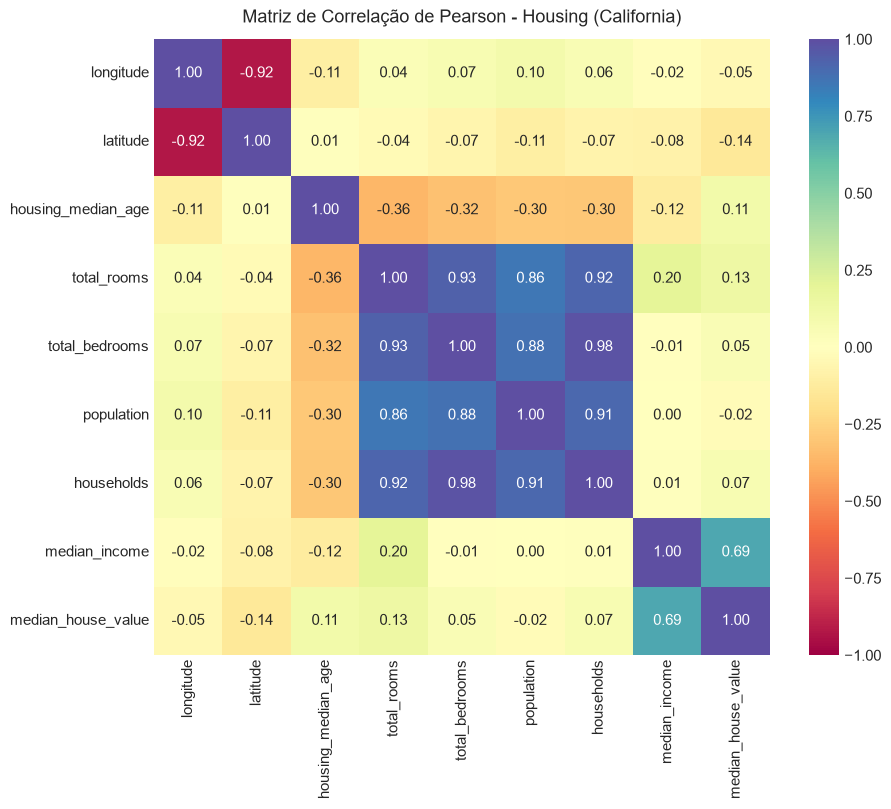

In [9]:
# Matriz de Correlação de Pearson para Housing
plt.figure(figsize=(10, 8))
housing_corr = df_housing.select_dtypes(include=[np.number]).corr()
sns.heatmap(housing_corr, annot=True, fmt=".2f", cmap='Spectral', center=0, vmin=-1, vmax=1, square=True)
plt.title("Matriz de Correlação de Pearson - Housing (California)", fontsize=13, pad=12)
plt.show()

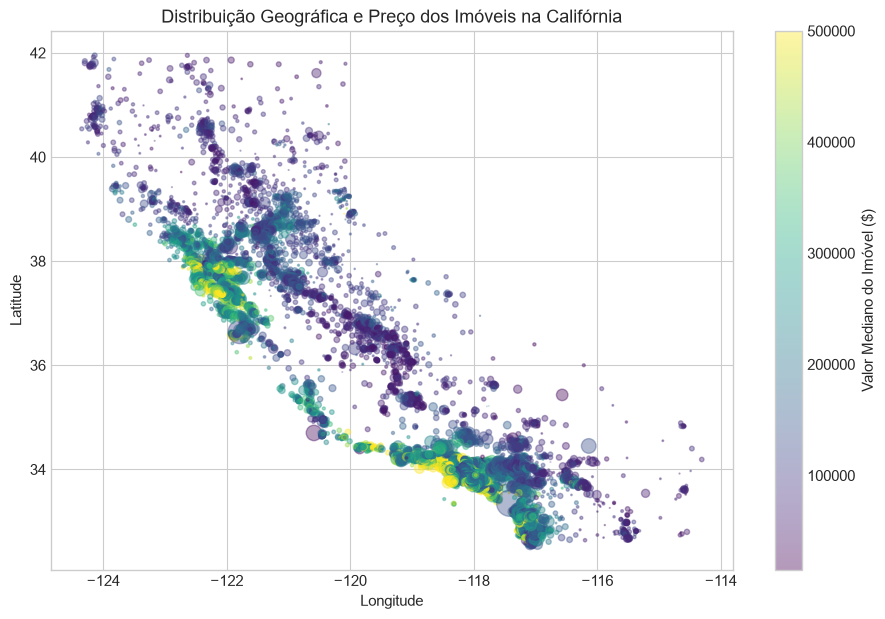

In [10]:
# Análise espacial: Mapa geográfico da Califórnia (Latitude vs Longitude)
plt.figure(figsize=(11, 7))
scatter = plt.scatter(
    df_housing['longitude'], 
    df_housing['latitude'], 
    c=df_housing['median_house_value'], 
    cmap='viridis', 
    alpha=0.4, 
    s=df_housing['population']/100, 
    label='População'
)
plt.colorbar(scatter, label='Valor Mediano do Imóvel ($)')
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Distribuição Geográfica e Preço dos Imóveis na Califórnia", fontsize=13)
plt.show()

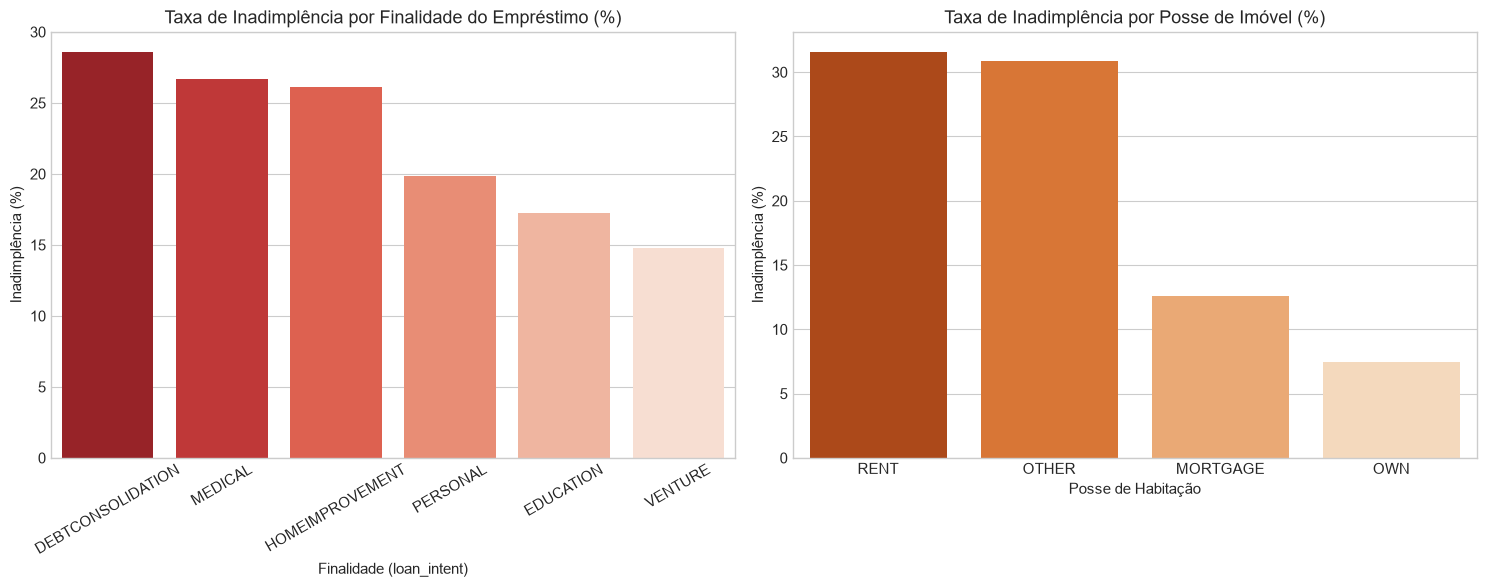

In [11]:
# Home Credit: Taxa de Inadimplência por Finalidade do Empréstimo e Posse de Habitação
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

intent_risk = df_credit.groupby('loan_intent')['loan_status'].mean().sort_values(ascending=False) * 100
sns.barplot(x=intent_risk.index, y=intent_risk.values, hue=intent_risk.index, legend=False, ax=axes[0], palette='Reds_r')
axes[0].set_title("Taxa de Inadimplência por Finalidade do Empréstimo (%)")
axes[0].set_xlabel("Finalidade (loan_intent)")
axes[0].set_ylabel("Inadimplência (%)")
axes[0].tick_params(axis='x', rotation=30)

home_risk = df_credit.groupby('person_home_ownership')['loan_status'].mean().sort_values(ascending=False) * 100
sns.barplot(x=home_risk.index, y=home_risk.values, hue=home_risk.index, legend=False, ax=axes[1], palette='Oranges_r')
axes[1].set_title("Taxa de Inadimplência por Posse de Imóvel (%)")
axes[1].set_xlabel("Posse de Habitação")
axes[1].set_ylabel("Inadimplência (%)")

plt.tight_layout()
plt.show()

## 5. Deteção de Anomalias e Outliers

A identificação de anomalias estatísticas é determinante para selecionar estratégias de pré-processamento e evitar distorções nos algoritmos de particionamento e distância euclidiana.


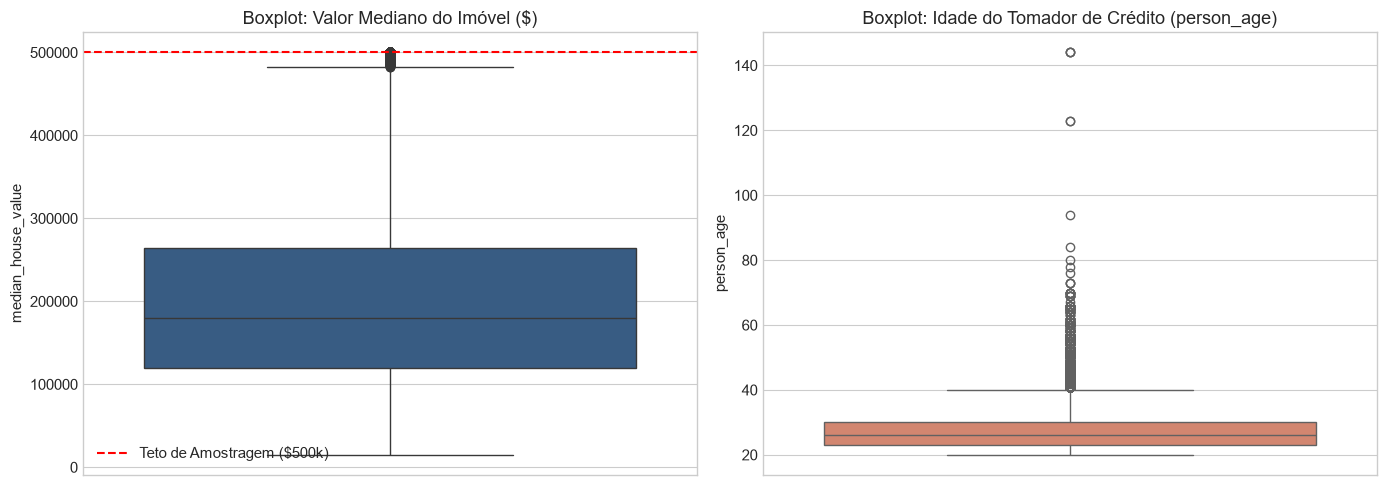

Registos no teto censitário ($500.000) no Housing: 992 (4.81%)
Registos com idade > 100 anos no Home Credit: 5


In [12]:
# Verificação de teto artificial (ceiling effect) e outliers via Boxplots
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(y=df_housing['median_house_value'], ax=axes[0], color='#2b5c8f')
axes[0].set_title("Boxplot: Valor Mediano do Imóvel ($)")
axes[0].axhline(500001, color='red', linestyle='--', label='Teto de Amostragem ($500k)')
axes[0].legend()

sns.boxplot(y=df_credit['person_age'], ax=axes[1], color='#e27d60')
axes[1].set_title("Boxplot: Idade do Tomador de Crédito (person_age)")

plt.tight_layout()
plt.show()

# Quantificação das anomalias
n_capped = np.sum(df_housing['median_house_value'] >= 500000)
print(f"Registos no teto censitário ($500.000) no Housing: {n_capped} ({n_capped/len(df_housing)*100:.2f}%)")

unrealistic_age = df_credit[df_credit['person_age'] > 100]
print(f"Registos com idade > 100 anos no Home Credit: {len(unrealistic_age)}")

## 6. Conclusões e Lições Aprendidas

### Síntese dos Achados Estatísticos:
1. **Housing (Califórnia):**
   - A variável `median_income` possui a mais forte correlação positiva com `median_house_value` ($r pprox 0.69$), sendo o preditor dominante do poder de compra e valor dos imóveis.
   - Observa-se um **teto artificial (*clipping*)** evidente em $\$500.001$, correspondente a cerca de $4.7\%$ da base censitária.
   - A coluna `total_bedrooms` apresenta $207$ valores ausentes ($1\%$), exigindo imputação robusta via mediana por bloco/região.
   - A dependência espacial é pronunciada: habitações situadas na costa marítima (`<1H OCEAN`, `NEAR OCEAN`, `NEAR BAY`) exibem valor mediano sistematicamente superior aos do interior (`INLAND`).

2. **Home Credit (Risco de Incumprimento):**
   - O conjunto exibe **desbalanceamento moderado de classes**, com cerca de $21.8\%$ de casos positivos de *default* (`loan_status = 1`). A métrica de avaliação primária não deve ser a acurácia isolada, mas sim **F1-Score (macro)** e **Revocação (*Recall*)**, priorizando a detecção de risco.
   - A variável `loan_percent_income` (percentual da renda comprometido com a parcela) e a taxa de juro `loan_int_rate` são os fatores com maior separabilidade empírica entre bons e maus pagadores.
   - Inquilinos (`RENT`) apresentam taxa de incumprimento superior ao dobro daqueles com imóvel quitado (`OWN`) ou hipotecado (`MORTGAGE`).

### Lições Aprendidas e Decisões de Modelagem:
* **Para a Árvore de Decisão (`02_classify.ipynb`):** O algoritmo *from scratch* deve contemplar divisão estratificada (`train_test_split`), ponderação ou foco em *Recall* para mitigar o viés em favor da classe majoritária, e codificação One-Hot para atributos categóricos (`loan_intent`, `person_home_ownership`, `loan_grade`).
* **Para o K-Means (`03_clusters.ipynb`):** A normalização das variáveis via `StandardScaler` é estritamente obrigatória antes do cálculo de distâncias euclidianas, evitando que atributos com amplitudes elevadas (ex.: população ou valor do imóvel) dominem as coordenadas geográficas.
* **Para as Regras de Associação (`04_assoc_rules.ipynb`):** A discretização em intervalos explicativos (*binning* de renda, valor de habitação e faixas de risco) é necessária para transformar matrizes contínuas em formato transacional legível.
